# General workflow for ligand $pK_A$ estimation
## This notebook illustrates the application of MolGpKa for the calculation of $pK_A$ values using their trained CNN.

## The code in this cell is the basic structure to run the trained model on a molecule to predict the $pK_A$ values

In [1]:
from rdkit import Chem
from rdkit.Chem import AllChem, Draw
from rdkit import RDLogger
RDLogger.DisableLog('rdApp.*')
from rdkit.Chem.MolStandardize import rdMolStandardize

import os.path as osp
import numpy as np
import pandas as pd

import torch
from utils.ionization_group import get_ionization_aid
from utils.descriptor import mol2vec
from utils.net import GCNNet
import py3Dmol
import ipywidgets as widgets

root = osp.abspath("")

def load_model(model_file, device="cpu"):
    model= GCNNet().to(device)
    model.load_state_dict(torch.load(model_file, map_location=device, weights_only=True))
    model.eval()
    return model

def model_pred(m2, aid, model, device="cpu"):
    data = mol2vec(m2, aid)
    with torch.no_grad():
        data = data.to(device)
        pKa = model(data)
        pKa = pKa.cpu().numpy()
        pka = pKa[0][0]
    return pka

def predict_acid(mol):
    model_file = osp.join(root, "../models/weight_acid.pth")
    model_acid = load_model(model_file)

    acid_idxs= get_ionization_aid(mol, acid_or_base="acid")
    acid_res = {}
    for aid in acid_idxs:
        apka = model_pred(mol, aid, model_acid)
        acid_res.update({aid:apka})
    return acid_res

def predict_base(mol):
    model_file = osp.join(root, "../models/weight_base.pth")
    model_base = load_model(model_file)

    base_idxs= get_ionization_aid(mol, acid_or_base="base")
    base_res = {}
    for aid in base_idxs:
        bpka = model_pred(mol, aid, model_base) 
        base_res.update({aid:bpka})
    return base_res

def predict(mol, uncharged=True):
    if uncharged:
        un = rdMolStandardize.Uncharger()
        mol = un.uncharge(mol)
        mol = Chem.MolFromSmiles(Chem.MolToSmiles(mol))
    mol = AllChem.AddHs(mol)
    base_dict = predict_base(mol)
    acid_dict = predict_acid(mol)
    AllChem.EmbedMolecule(mol)
    return base_dict, acid_dict, mol

/Users/brookscl/miniforge3/envs/molgpk_new/lib/python3.12/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


## Worker routines to process the pH-dependent tautomer structures

In [4]:
def drawit(m, atom_idxs, pkas, p=None, confId=-1):
    """
    Draws a side-by-side display of 3D representation of molecule with pK_A value labels on titratable atoms
    Parameters:
    -----------
    m  ==> original mol containing all hydrogen atoms
    atom_idxa ==> list of indexes of atoms where hydrogens are added/removed depending on pH
    pkas ==> list of pK_A values of titratable atoms as determined by MolGPka
    p ==> current 3D view from py3D
    confId ==> particular co nfiguration to display (default -1)
    
    """
    mb = Chem.MolToMolBlock(m, confId=confId)
    if p is None:
        p = py3Dmol.view(width=1000, height=400)
    p.removeAllModels()
    p.addModel(mb, 'sdf')
    for pka, idx in zip(pkas, atom_idxs):
        pos = m.GetConformer().GetAtomPosition(idx)
        label = "pKa={:.3}".format(round(pka, 1))
        p.addLabel(label, {"position": {"x": pos.x, "y":pos.y, "z": pos.z}, "fontSize":10})
    p.setStyle({'stick':{'colorscheme':'greenCarbon'}})
    p.setBackgroundColor('0xeeeeee')
    p.zoomTo()
    return p.show()
def drawit2(m, atom_idxs, pkas, p=None, confId=-1):
    """
    Draws a side-by-side display of 3D representation of molecule with pK_A value labels on titratable atoms
    Parameters:
    -----------
    m  ==> original mol containing all hydrogen atoms
    atom_idxa ==> list of indexes of atoms where hydrogens are added/removed depending on pH
    pkas ==> list of pK_A values of titratable atoms as determined by MolGPka
    p ==> current 3D view from py3D
    confId ==> particular co nfiguration to display (default -1)
    
    """
    import io
    import ipywidgets as widgets
    from IPython.display import display

    # Generate the PIL image at your desired size (e.g., 600x600)
    pil_img = Draw.MolToImage(m, size=(400, 400))
    
    # FIX: Save the PIL image into a proper PNG byte stream
    img_byte_arr = io.BytesIO()
    pil_img.save(img_byte_arr, format='PNG')
    img_bytes = img_byte_arr.getvalue()
    
    # Create the Widget with matching layout dimensions
    rdkit_widget = widgets.Image(
        value=img_bytes,
        format='png',
        layout=widgets.Layout(width='400px', height='400px')
    )

    # 2. Setup a standard ipywidgets Output container for py3Dmol
    py3d_output_container = widgets.Output(layout=widgets.Layout(width='400px', height='400px'))


    mb = Chem.MolToMolBlock(m, confId=confId)
    if p is None:
        p = py3Dmol.view(width=400, height=400)
    p.removeAllModels()
    p.addModel(mb, 'sdf')
    for pka, idx in zip(pkas, atom_idxs):
        pos = m.GetConformer().GetAtomPosition(idx)
        label = "pKa={:.3}".format(round(pka, 1))
        p.addLabel(label, {"position": {"x": pos.x, "y":pos.y, "z": pos.z}, "fontSize":10})
    p.setStyle({'stick':{'colorscheme':'greenCarbon'}})
    p.setBackgroundColor('0xeeeeee')
    p.zoomTo()
    with py3d_output_container:
        p.show()  
    
    # 4. Put them side-by-side using HBox
    side_by_side_layout = widgets.HBox([py3d_output_container, rdkit_widget])
    
    # 5. Render to your notebook
    display(side_by_side_layout)
    return
def write_mol2(mol=None,filename='molecule.mol2'):
    """
    Writes a mol2 file to disk from an RDKit mol by converting the mol file to a PDBBlock and then
    to a mol2 using openbabel pybel
    Parameters:
    -----------
    mol ==> mol object write as mol2 file
    filename ==> name of mol2 file to write    
    """
    from openbabel import pybel
    pybel_mol = pybel.readstring('pdb', Chem.MolToPDBBlock(mol))
    pybel_mol.write('mol2', filename, overwrite=True)
    return
def set_uniqueNames(mol=None):
    """
    Names atoms in mol object to unique names based on atom type and
    occurance of atom in list.
    Residue is also named LIG
    Parameters:
    -----------
    mol ==> mol object to process
    
    Returns:
    --------
    mol  ==> mol object with atom name and residue name properties added
     """
    # Set names
    # Assign custom names to the 'molFileAlias' property of each atom
    for i, atom in enumerate(mol.GetAtoms()):
        name = f'{atom.GetSymbol()}{i+1}'
        atom.SetProp('molFileAlias', name)
        # Create the PDB residue info object
        info = Chem.AtomPDBResidueInfo(
            atomName=name.ljust(4), 
            residueName='LIG', 
            residueNumber=1
        )
        atom.SetMonomerInfo(info)
    return mol

def apply_modifications_from_all_h_file(base_mol, additions=None, removals=None):
    """
    Correctly generates the zwitterion from an all-hydrogen base molecule
    by altering charges first and removing the explicit hydrogen atoms.
    Parameters:
    -----------
    base_mol  ==> original mol containing all hydrogen atoms
    additions ==> indexes of atoms to add hydrogens to
    removals ==> indexes of atoms to remove hydrogen from

    Returns:
    --------
    final_mol ==> final molecule with additions/deletions of hydrogen atoms
    """
    additions = additions or []
    removals = removals or []
    
    # Track the exact formal charge modifications needed on the heavy atoms
    charge_adjustments = {}
    
    # 1. Map additions (+1 charge directly to the targeted heavy atom)
    for idx in additions:
        charge_adjustments[idx] = charge_adjustments.get(idx, 0) + 1
        
    # 2. Map removals (-1 charge to the heavy atom holding the target hydrogen)
    for h_idx in removals:
        h_atom = base_mol.GetAtomWithIdx(h_idx)
        if h_atom.GetSymbol() != 'H':
            raise ValueError(f"Atom at index {h_idx} is not a Hydrogen!")
        
        # Identify its parent heavy atom neighbor
        parent_heavy_idx = h_atom.GetNeighbors()[0].GetIdx()
        charge_adjustments[parent_heavy_idx] = charge_adjustments.get(parent_heavy_idx, 0) - 1

    # 3. Create a deep copy of the molecule to manipulate charges safely
    mol_copy = Chem.Mol(base_mol)
    for idx, delta_charge in charge_adjustments.items():
        atom = mol_copy.GetAtomWithIdx(idx)
        atom.SetFormalCharge(atom.GetFormalCharge() + delta_charge)
        
    # 4. Remove the targeted explicit hydrogen atoms using EditableMol in descending order
    emol = Chem.EditableMol(mol_copy)
    for h_idx in sorted(removals, reverse=True):
        emol.RemoveAtom(h_idx)
        
    final_mol = emol.GetMol()
    
    # 5. Clean up any remaining explicit hydrogens to implicit representation
    final_mol = Chem.RemoveHs(final_mol)
    
    # 6. Sanitize to re-evaluate the explicit changes we forced onto the molecule
    Chem.SanitizeMol(final_mol)
    
    return final_mol
def draw_molecules(molecule_data):
    """
    Draws a panel of molecules to view protonation states and charge    
    Parameters:
    -----------
    molecule_data dictionary of keys ==> molecule labels and values ==> mol files
    Returns:
    --------
    img ==> image to display panel of molecules
    """
    from rdkit import Chem
    from rdkit.Chem import Draw
    
   
    # 1. Parse SMILES strings into RDKit molecules
    mols = []
    for smiles in molecule_data.values():
        print(smiles)
        mols.append(Chem.MolFromSmiles(smiles))
    legends = list(molecule_data.keys())
    
    # 2. Generate the grid image
    # Jupyter automatically picks up this object and displays it on screen
    img = Draw.MolsToGridImage(
        mols, 
        molsPerRow=2,         # Sets a 2-column panel layout
        subImgSize=(400, 400), # Height & width for each sub-molecule box
        legends=legends       # List of strings printed below each structure
    )
    
    # 4. Explicitly show on screen
    return img
def compute_microstate_fractions(pka_values, interactions, ph):
    """
    Computes the fractional populations of protonation microstates.
    
    Parameters:
    -----------
    pka_values : list or np.array
        Intrinsic pKa values for each titratable site.
    interactions : np.array
        Square matrix (N x N) of interaction energies between sites (in pH units).
        interactions[j, k] is the interaction between site j and site k.
    ph : float
        The pH at which to calculate the fractions.
        
    Returns:
    --------
    microstates : list of tuples
        The binary representation of each microstate (e.g., (1, 0, 1)).
    fractions : np.array
        The fractional population of each microstate (sums to 1.0).
    site_protonation : np.array
        The net fractional protonation of each individual site.
    """
    num_sites = len(pka_values)
    num_states = 2 ** num_sites
    
    # Generate all 2^N microstates (binary combinations)
    microstates = []
    for i in range(num_states):
        # Convert integer to binary list of length num_sites
        state = [int(x) for x in format(i, f'0{num_sites}b')]
        microstates.append(tuple(state))
        
    microstates = np.array(microstates)
    weights = np.zeros(num_states)
    
    # Calculate the statistical weight for each microstate
    for i, state in enumerate(microstates):
        # Intrinsic pKa contribution: sum(x_j * pKa_j)
        pka_term = np.sum(state * pka_values)
        
        # pH contribution: sum(x_j * pH)
        ph_term = np.sum(state * ph)
        
        # Interaction term: sum(x_j * x_k * epsilon_jk) for j < k
        interaction_term = 0.0
        for j in range(num_sites):
            for k in range(j + 1, num_sites):
                interaction_term += state[j] * state[k] * interactions[j, k]
                
        # Net log10 weight
        log_weight = pka_term - ph_term - interaction_term
        weights[i] = 10 ** log_weight
        
    # Calculate partition function (sum of all weights)
    partition_function = np.sum(weights)
    
    # Calculate fractional populations
    fractions = weights / partition_function
    
    # Calculate net protonation per site by summing over occupying microstates
    site_protonation = np.dot(fractions, microstates)
    
    return [tuple(s) for s in microstates], fractions, site_protonation
from rdkit import Chem
from rdkit.Chem import AllChem, rdFMCS

def generate_superposed_3d_with_global_h_names(template_mol, smiles_list, output_prefix="lig"):
    """Generates 3D conformations for a list of SMILES that are strictly 
    minimized and rigidly superposed against a 3D template's heavy atom core.
    """
    # 1. Ensure template has a valid 3D conformation for alignment reference
    if template_mol.GetNumConformers() == 0:
        print("Template lacks 3D coordinates! Generating template reference 3D...")
        template_mol = Chem.AddHs(template_mol)
        tpl_embed_params = AllChem.ETKDGv3()
        tpl_embed_params.randomSeed = 42
        AllChem.EmbedMolecule(template_mol, tpl_embed_params)
        AllChem.MMFFOptimizeMolecule(template_mol)
        template_mol = Chem.RemoveHs(template_mol)
    else:
        template_mol = Chem.RemoveHs(template_mol)

    # Configure MCS for element-only heavy atom mapping
    mcs_params = rdFMCS.MCSParameters()
    mcs_params.AtomTyper = rdFMCS.AtomCompare.CompareElements
    
    for idx, smiles in enumerate(smiles_list):
        target_mol = Chem.MolFromSmiles(smiles)
        if target_mol is None: 
            print(f"Skipping invalid SMILES: {smiles}")
            continue
            
        # 2. Find the matching heavy atom core between template and target
        mcs_result = rdFMCS.FindMCS([template_mol, target_mol], mcs_params)
        core_query = Chem.MolFromSmarts(mcs_result.smartsString)
        
        template_matches = template_mol.GetSubstructMatch(core_query)
        target_matches = target_mol.GetSubstructMatch(core_query)
        idx_map = {tgt: tpl for tpl, tgt in zip(template_matches, target_matches)}
        
        # 3. Propagate heavy atom names to the target skeleton
        for tgt_idx in range(target_mol.GetNumAtoms()):
            tgt_atom = target_mol.GetAtomWithIdx(tgt_idx)
            if tgt_idx in idx_map:
                tpl_info = template_mol.GetAtomWithIdx(idx_map[tgt_idx]).GetPDBResidueInfo()
                if tpl_info is not None:
                    new_info = Chem.AtomPDBResidueInfo()
                    new_info.SetName(tpl_info.GetName()) 
                    new_info.SetResidueName(tpl_info.GetResidueName())
                    new_info.SetResidueNumber(tpl_info.GetResidueNumber())
                    tgt_atom.SetMonomerInfo(new_info)

        # 4. Add Hydrogens prior to structural embedding
        target_mol = Chem.AddHs(target_mol)
        
        # 5. EMBEDDING WITH CORRECTED FALLBACK
        try:
            # First try the constrained tether approach
            target_mol = AllChem.ConstrainedEmbed(target_mol, template_mol, useTethers=True, randomseed=42)
        except Exception as e:
            print(f"Constrained/Tethered embedding failed for {smiles}. Falling back to unconstrained. Info: {e}")
            
            # FIXED fallback parameter configurations
            fallback_params = AllChem.ETKDGv3()
            fallback_params.randomSeed = 42
            fallback_params.useRandomCoords = True # Helps highly-charged/protonated rings converge
            
            # Removed the extra trailing randomSeed=42 argument from the function signature below
            AllChem.EmbedMolecule(target_mol, fallback_params)
        
        if target_mol.GetNumConformers() == 0:
            print(f"Embedding failed completely for {smiles}")
            continue

        # 6. INITIAL COORD SEED: Overwrite target's core positions with template positions
        conf_target = target_mol.GetConformer()
        conf_template = template_mol.GetConformer()
        for tgt_idx, tpl_idx in idx_map.items():
            tpl_pos = conf_template.GetAtomPosition(tpl_idx)
            conf_target.SetAtomPosition(tgt_idx, tpl_pos)

        # 7. RESTRAINED MINIMIZATION (Hydrogens relax, heavy atom core stays put)
        try:
            ff_props = AllChem.MMFFGetMoleculeProperties(target_mol)
            ff = AllChem.MMFFGetMoleculeForceField(target_mol, ff_props)
            
            # Strict position constraints on the preset heavy coordinates
            for tgt_idx in idx_map.keys():
                ff.MMFFAddPositionConstraint(tgt_idx, 0.0, 1.0e5)
                
            ff.Minimize(maxIts=500)
        except Exception as e:
            print(f"Optimization warning for {smiles}: {e}")

        # 8. STRUCTURAL SUPERPOSITION PASS
        alignment_map = [(tgt, tpl) for tgt, tpl in idx_map.items()]
        rmsd = AllChem.AlignMol(target_mol, template_mol, atomMap=alignment_map)

        # 9. DETERMINISTIC HYDROGEN NAMING (Based on perfectly stacked coordinates)
        conf = target_mol.GetConformer()
        for atom in target_mol.GetAtoms():
            if atom.GetSymbol() == "H": 
                continue
                
            parent_info = atom.GetPDBResidueInfo()
            if parent_info:
                parent_suffix = parent_info.GetName().strip()[1:]
            else:
                parent_suffix = str(atom.GetIdx())

            h_neighbors = [nbr for nbr in atom.GetNeighbors() if nbr.GetSymbol() == "H"]
            
            # Sort by absolute coordinate quadrants
            h_neighbors.sort(key=lambda h: (round(conf.GetAtomPosition(h.GetIdx()).x, 1), 
                                            round(conf.GetAtomPosition(h.GetIdx()).y, 1), 
                                            round(conf.GetAtomPosition(h.GetIdx()).z, 1)))
            
            alphabet = "ABCDEFGHIJ"
            for h_rank, h_atom in enumerate(h_neighbors):
                h_custom_name = f"H{parent_suffix}{alphabet[h_rank]}"
                padded_h_name = f"{h_custom_name:<3}"
                
                h_info = Chem.AtomPDBResidueInfo(padded_h_name, residueName="LIG", residueNumber=1)
                h_atom.SetMonomerInfo(h_info)

        # 10. Write file out to disk
        #filename = f"{output_prefix}_state_{idx}.pdb"
        #writer = Chem.PDBWriter(filename)
        #writer.write(target_mol)
        #writer.close()
        #print(f"Successfully superposed state: '{filename}' | Heavy Core RMSD to Template: {rmsd:.4f} Å")
        # 10. Write file out to disk
        filename = f"{output_prefix}_state_{idx}.mol2"
        write_mol2(mol=target_mol,filename=filename)
        print(f"Successfully superposed state: '{filename}' | Heavy Core RMSD to Template: {rmsd:.4f} Å")

def write_superposed_mol2(list_mols = {}):
    # ==========================================
    # RUNNING THE PIPELINE
    # ==========================================
    protonation_smiles_series = []
    atom_labels = []
    for k in list_mols.keys():
        #print(f'Working on {k}')
        if 'Reference' in k:
            #print(list_mols[k])
            template = Chem.MolFromSmiles(list_mols[k])
            for iatm, atom in enumerate(template.GetAtoms()):
                atom_labels.append(f'{atom.GetSymbol()}{iatm}')
            for index, name in enumerate(atom_labels):
                template.GetAtomWithIdx(index).SetMonomerInfo(Chem.AtomPDBResidueInfo(f" {name:<4}", residueName="LIG", residueNumber=1))
            protonation_smiles_series.append(list_mols[k])
        else:
            # Your list of pure SMILES strings varying in protonation states
            protonation_smiles_series.append(list_mols[k])
    # Run the 3D execution loop
    generate_superposed_3d_with_global_h_names(template, protonation_smiles_series, output_prefix="lig")
    return

> * ## set-up molecule as smiles string or alternatively read from list of smiles or sdf file
> * ## use RDKit to convert to mol
> * ## print $pK_A$ values
> * ## draw molecule
> * ## compute occupation at given pH
> * ## show image of relevant structures
> * ## write mol2 files for each tautomer

Atom Index 8: N9 pK_A 6.5
Atom Index 10: N11 pK_A 6.0
Atom Index 11: N12 pK_A 6.7
Atom Index 13: N14 pK_A 5.4
Atom Index 28: H29 pK_A 13.6
Atom Index 29: H30 pK_A 13.6
Atom Index 30: H31 pK_A 13.2
Atom Index 31: H32 pK_A 13.2


3Dmol.js failed to load for some reason. Please check your browser console for error messages.

--- Microstates at pH 6.0 ---
 State (1, 0, 1, 0, 1, 1, 1, 1): 0.258
 State (1, 1, 1, 0, 1, 1, 1, 1): 0.239
 State (0, 0, 1, 0, 1, 1, 1, 1): 0.084
 State (0, 1, 1, 0, 1, 1, 1, 1): 0.078
 State (1, 0, 1, 1, 1, 1, 1, 1): 0.066
 State (1, 1, 1, 1, 1, 1, 1, 1): 0.061
 State (1, 0, 0, 0, 1, 1, 1, 1): 0.055
 State (1, 1, 0, 0, 1, 1, 1, 1): 0.051
species 8 15 matches reference (0, 0, 0, 0, 1, 1, 1, 1) (0, 0, 0, 0, 1, 1, 1, 1)
 State (0, 0, 0, 0, 1, 1, 1, 1): 0.018
Template lacks 3D coordinates! Generating template reference 3D...
Successfully superposed state: 'lig_state_0.mol2' | Heavy Core RMSD to Template: 0.0000 Å
Successfully superposed state: 'lig_state_1.mol2' | Heavy Core RMSD to Template: 0.0002 Å
Successfully superposed state: 'lig_state_2.mol2' | Heavy Core RMSD to Template: 0.0003 Å
Successfully superposed state: 'lig_state_3.mol2' | Heavy Core RMSD to Template: 0.0001 Å
Successfully superposed state: 'lig_state_4.mol2' | Heavy Core RMSD to Template: 0.0002 Å
Successfully superpos

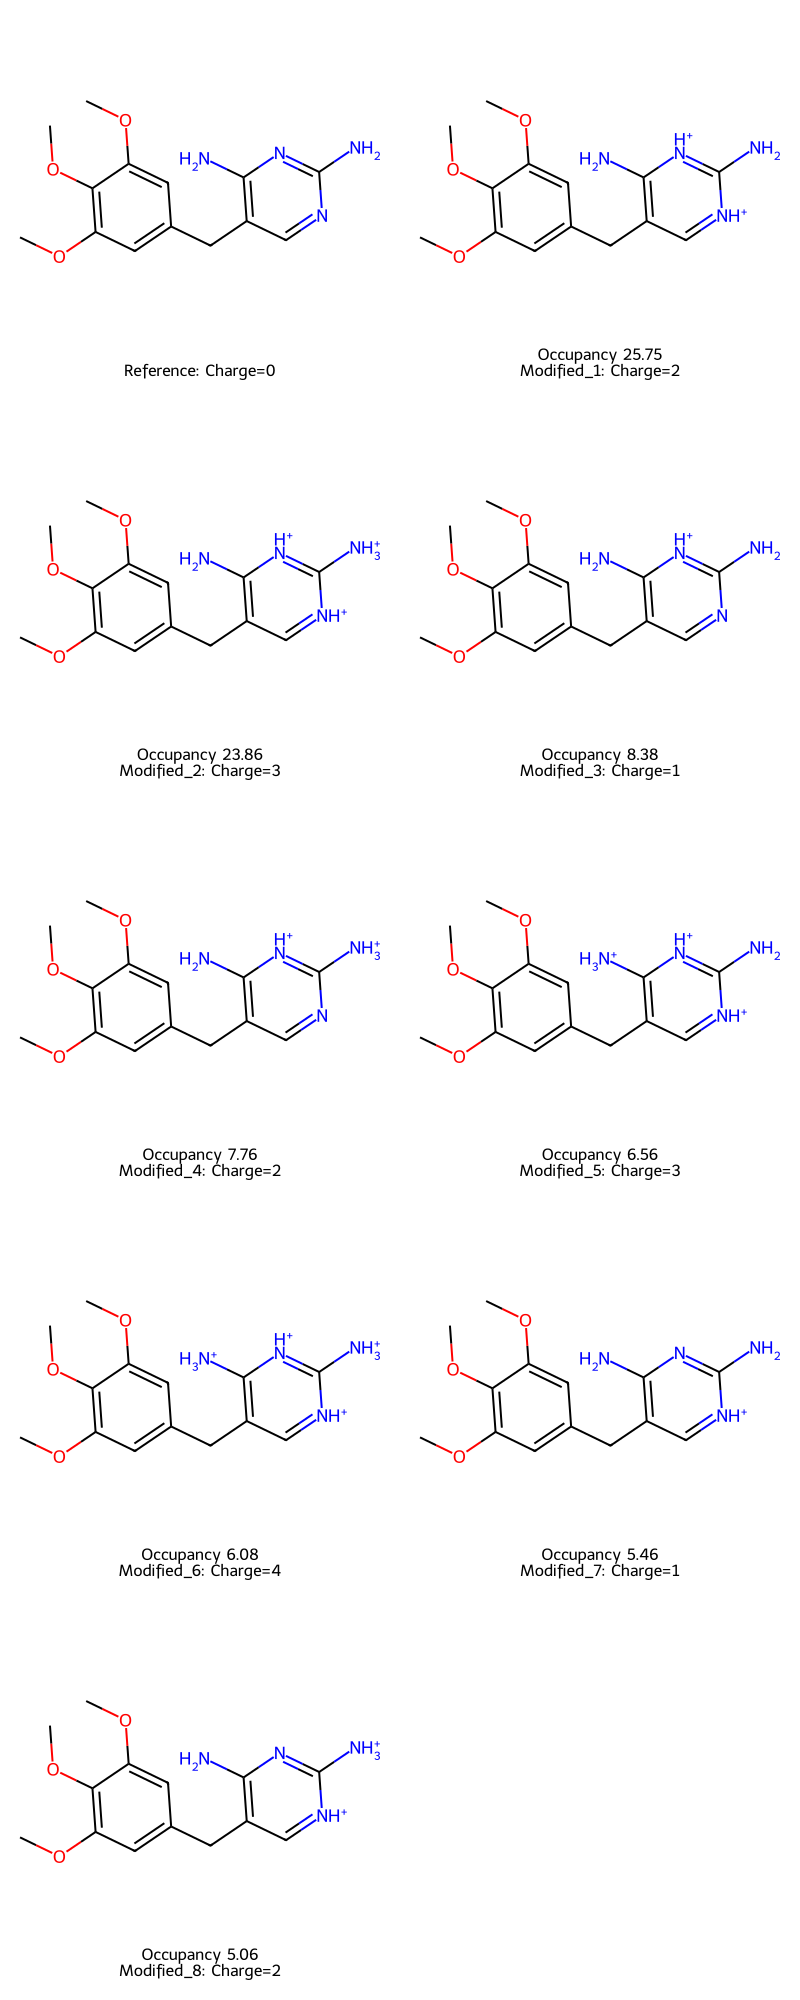

In [5]:
#####################Input Parameters#####################
target_ph = 6.0 # pH value at which to construct tautomer distribution
molname = 'tmp' # name for the 
smi = 'COC1=CC(CC2=CN=C(N)N=C2N)=CC(OC)=C1OC'  # trimethoprim
#molname = input('Input the name of this molecule')
#smi = input('Input the smiles string to process')
#target_ph = input('Input the target pH')
mol = Chem.MolFromSmiles(smi)
# Set names
# Assign custom/unique names to the 'molFileAlias' property of each atom
for i, atom in enumerate(mol.GetAtoms()):
    name = f'{atom.GetSymbol()}{i+1}'
    atom.SetProp('molFileAlias', name)
# Call MolGpKA predict to predict the pK_A values
base_dict, acid_dict, m = predict(mol)
atom_idx = list(base_dict.keys()) + list(acid_dict.keys()) # atom_idx is a list of the atom indexes that are ionizable
pkas = list(base_dict.values()) + list(acid_dict.values()) # pkas is a list of the pK_A values for atoms
m = set_uniqueNames(mol=m)
# Construct the annotated molecule with labeled titration sites
ref_tuple = []
atoms_to_change = {'index':[],'name':[],'pka':[]}
for i,idx in enumerate(atom_idx):
    atom = m.GetAtomWithIdx(idx)
    # Check if the alias property exists
    if atom.HasProp('molFileAlias'):
        atom_name = atom.GetProp('molFileAlias')
    atoms_to_change['index'].append(idx)
    atoms_to_change['name'].append(atom_name)
    if atom_name[0] == 'H': ref_tuple.append(1)
    else: ref_tuple.append(0)
    atoms_to_change['pka'].append(pkas[i])
    print(f'Atom Index {idx}: {atom_name} pK_A {pkas[i]:.1f}')
drawit(m, atom_idx, pkas)
# make a copy of the reference molecule
ref_mol = m
ref_tuple = tuple(ref_tuple)

# recas the pK_A values to a np array
site_pkas = np.array(pkas) 

# Interaction matrix is assumed to be all zeros, but this could be tuned if substituient affects were known
site_interactions = np.zeros((site_pkas.shape[0],site_pkas.shape[0]))
# Construct the microstates for this molecule with the computed pK_A values
states, micro_fracs, site_fracs = compute_microstate_fractions(
    site_pkas, site_interactions, target_ph
)

print(f"--- Microstates at pH {target_ph} ---")
idx_state = 0
states_dict = {}
for state, frac in zip(states, micro_fracs):
    states_dict[idx_state]=(frac,state)
    idx_state += 1
# 1. Sort by the float element (index 0 of the value)
sorted_items = sorted(states_dict.items(), key=lambda item: item[1][0],reverse=True)
# 2. Convert the sorted list of tuples back into a dictionary
sorted_dict = dict(sorted_items)

n_species = 0
# Construct a list of molecules and formal charge for reference molecule
list_mols = {f'Reference: Charge={Chem.GetFormalCharge(ref_mol)}':Chem.MolToSmiles(ref_mol)}

# Populate the list for all tautomers with population above 5%
for key in sorted_dict.keys():
    add_to = []
    remove_from = []
    if tuple(map(int,sorted_dict[key][1])) == ref_tuple:
        print(f'species {n_species} {key} matches reference {tuple(map(int,sorted_dict[key][1]))} {ref_tuple}')
        ref_key = key
    # Minimum population tautomer given below (.05/5%)
    if sorted_dict[key][0] >= 0.05 or tuple(map(int,sorted_dict[key][1])) == ref_tuple:  
        n_species += 1
        print(f' State {tuple(map(int,sorted_dict[key][1]))}: {sorted_dict[key][0]:.3f}')
        for j, change in enumerate(tuple(map(int,sorted_dict[key][1]))):
            if not change and atoms_to_change['name'][j][0] == 'H':
                #print(f'Testing hydrogen remove {atoms_to_change['index'][j]}:{atoms_to_change['name'][j]}')
                remove_from.append(atoms_to_change['index'][j])
            elif change and atoms_to_change['name'][j][0] != 'H':
                add_to.append(atoms_to_change['index'][j])
        new_mol = apply_modifications_from_all_h_file(ref_mol, additions=add_to, removals=remove_from)
        if tuple(map(int,sorted_dict[key][1])) == ref_tuple:
            list_mols[f'Reference: Charge={Chem.GetFormalCharge(ref_mol)}']=Chem.MolToSmiles(new_mol)
        else: 
            list_mols[f'Occupancy {sorted_dict[key][0]*100:.2f}\nModified_{n_species}: Charge={Chem.GetFormalCharge(new_mol)}']=Chem.MolToSmiles(new_mol)
write_superposed_mol2(list_mols = list_mols)
draw_molecules(list_mols)

## Based on the computed $pK_A$ values plot the titration curve

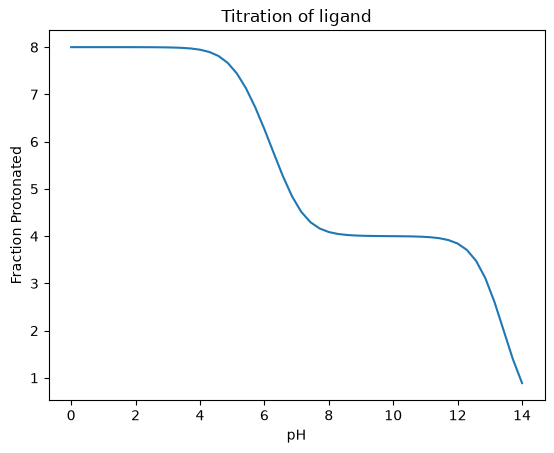

In [4]:
from matplotlib import pyplot as plt
import numpy as np
phs = np.linspace(0,14,50)
fhs = []
for pH in phs:
    fh = 0.0
    for pka in pkas:
       fh += 1/(1+10**(pH-pka)) 
    fhs.append(fh)
plt.plot(phs,fhs)
plt.xlabel('pH')
plt.ylabel('Fraction Protonated')
plt.title(f'Titration of ligand')
plt.show()